### Exploratory Data Analysis

In [1]:
import os
import json

import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from scipy.stats import pearsonr, wilcoxon

In [2]:
# file locations 
ISLES_2024_TRAIN = "../../data/processed/"
ISLES_2024_TEST = "../../data/processed_test/"
ISLES_2024_TRAINR = "../../data/raw/derivatives/"
ISLES_2024_TESTR = "../../data/raw_test/derivatives/"
ISLES_2022_TRAIN = "../../data/isles_2022_train/"
ISLES_2022_TEST = "../../data/isles_2022_test/"

train_2024 = [f.path for f in os.scandir(ISLES_2024_TRAIN) if f.is_dir()]
test_2024 = [f.path for f in os.scandir(ISLES_2024_TEST) if f.is_dir()]
trainr_2024 = [f.path for f in os.scandir(ISLES_2024_TRAINR) if f.is_dir()]
testr_2024 = [f.path for f in os.scandir(ISLES_2024_TESTR) if f.is_dir()]
train_2022 = [f.path for f in os.scandir(ISLES_2022_TRAIN) if f.is_dir()]
test_2022 = [f.path for f in os.scandir(ISLES_2022_TEST) if f.is_dir()]


print(f"Num files in isles 2024 train: {len(train_2024)}")
print(f"Num files in isles 2024 test: {len(test_2024)}")
print(f"Num files in isles 2024 train raw: {len(trainr_2024)}")
print(f"Num files in isles 2024 test raw: {len(testr_2024)}")


print(f"Num files in isles 2022 train: {len(train_2022)}")
print(f"Num files in isles 2022 test: {len(test_2022)}")

Num files in isles 2024 train: 115
Num files in isles 2024 test: 34
Num files in isles 2024 train raw: 115
Num files in isles 2024 test raw: 34
Num files in isles 2022 train: 174
Num files in isles 2022 test: 51


### Dataset analysis

In [3]:
raw_data_path = "/home/dayan/Documents/Datasets/stroke_segmentation/ISLES-2022"
dirs = os.listdir(raw_data_path)
dirs = sorted(dirs)
dirs = dirs[5:]


voxel_sizes = []
id = 1
for folder in dirs:
    path = f"{raw_data_path}/{folder}/ses-0001/dwi/{folder}_ses-0001_dwi.nii.gz"
    gt_path  = f"{raw_data_path}/derivatives/{folder}/ses-0001/{folder}_ses-0001_msk.nii.gz"
    dwi_image = nib.load(path)
    msk_image = nib.load(gt_path).get_fdata()
    voxel_volume = np.prod(dwi_image.header.get_zooms())/1000
    lesion_volume = np.sum(msk_image) * voxel_volume

    voxel_sizes.append({"Id":id, "lesion_vol": lesion_volume})
    id+=1
    
voxel_sizes = pd.DataFrame(voxel_sizes)
print(voxel_sizes.shape)
voxel_sizes.tail()

(250, 2)


,Id,lesion_vol
245,246,216.256010
246,247,18.256001
247,248,16.013596
248,249,11.251583
249,250,8.027989


I define the lesion categories as follows:
 - small: lesion volume < 5ml
 - medium: lesion volume >=5ml and < 20ml
 - large: lesion volume >= 20ml

In [4]:
def vol_count(arr):
    small_lesions = arr[(arr["lesion_vol"] < 5.0)]
    medium_lesions = arr[(arr["lesion_vol"] >= 5.0) & (arr["lesion_vol"] < 20.0)]
    large_lesions = arr[arr["lesion_vol"] >= 20]

    return small_lesions, medium_lesions, large_lesions

small, medium, large = vol_count(voxel_sizes)

print(f"small lesions: {small.shape[0]}")
print(f"medium lesions: {medium.shape[0]}")
print(f"large lesions: {large.shape[0]}")

small lesions: 104
medium lesions: 81
large lesions: 65


Check current train-test split volume distribution.

In [5]:
train = voxel_sizes.iloc[:169, :]
validation = voxel_sizes.iloc[170:199, :]
test = voxel_sizes.iloc[200:, :]

small, medium, large = vol_count(train)

print(small.head())
print(large.head())

print("Train")
smalls = small.shape[0]
mediums = medium.shape[0]
larges = large.shape[0]
print(f"small lesions: {smalls}")
print(f"medium lesions: {mediums}")
print(f"large lesions: {larges}")
print(f"Total samples: {smalls + mediums + larges}")

small, medium, large = vol_count(validation)

print("\nValidation")
smalls = small.shape[0]
mediums = medium.shape[0]
larges = large.shape[0]
print(f"small lesions: {smalls}")
print(f"medium lesions: {mediums}")
print(f"large lesions: {larges}")
print(f"Total samples: {smalls + mediums + larges}")

small, medium, large = vol_count(test)

print("\nTest")
smalls = small.shape[0]
mediums = medium.shape[0]
larges = large.shape[0]
print(f"small lesions: {smalls}")
print(f"medium lesions: {mediums}")
print(f"large lesions: {larges}")
print(f"Total samples: {smalls + mediums + larges}")

   Id  lesion_vol
1   2       0.944
3   4       2.248
5   6       0.040
6   7       3.512
7   8       0.752
    Id  lesion_vol
2    3   30.984001
12  13   29.160001
18  19   68.576003
22  23  482.152023
23  24   24.040001
Train
small lesions: 89
medium lesions: 38
large lesions: 42
Total samples: 169

Validation
small lesions: 5
medium lesions: 19
large lesions: 5
Total samples: 29

Test
small lesions: 9
medium lesions: 23
large lesions: 18
Total samples: 50


### Results Analysis

In [6]:
def load_jsonl(file_path:str):

    data = []
    with open(file_path) as f:
        for line in f:
            data.append(json.loads(line))
        
    df = pd.DataFrame(data)
    return df

### Load result paths

In [10]:
# new dual path model results
file_path_0_test = "../../metrics/test/0_BriAtt-Encoder_isles22_individual_metrics.jsonl"
file_path_0_train = "../../metrics/test/0_BriAtt-Encoder_isles22Train_individual_metrics.jsonl"

# UNet results i.e. baseline
file_path_21_test = "../../metrics/test/21_BriAtt-Encoder_isles22_individual_metrics.jsonl"
file_path_21_train = "../../metrics/test/21_BriAtt-Encoder_isles22Train_individual_metrics.jsonl"

# # single path bridger model
file_path_25_test = "../../metrics/test/25_BriAtt-Encoder_isles22_individual_metrics.jsonl"
file_path_25_train = "../../metrics/test/25_BriAtt-Encoder_isles22Train_individual_metrics.jsonl"

file_path_1_test = "../../metrics/test/3_BriAtt-Encoder_isles22_individual_metrics.jsonl"
file_path_1_train = "../../metrics/test/3_BriAtt-Encoder_isles22Train_individual_metrics.jsonl"

file_path_8_test = "../../metrics/test/exp_8_test.jsonl"

In [11]:
df_0_test = load_jsonl(file_path_0_test)
df_0_train = load_jsonl(file_path_0_train)

df_21_test = load_jsonl(file_path_21_test)
df_21_train = load_jsonl(file_path_21_train)

df_25_test = load_jsonl(file_path_25_test)
df_25_train = load_jsonl(file_path_25_train)

df_1_test = load_jsonl(file_path_1_test)
df_1_train = load_jsonl(file_path_1_train)

df_8_test = load_jsonl(file_path_8_test)

In [10]:
df_0_test.head()

,dice,jc,hd,asd,assd,precision,se,sp,F1
0,0.524524,0.355495,7.071068,1.554587,2.677407,0.937969,0.364054,0.999969,1.000000
1,0.761154,0.614406,6.708204,1.240338,2.075364,0.723751,0.802634,0.993576,0.421053
2,0.760062,0.612984,3.000000,0.942027,1.087258,0.773782,0.746820,0.999763,0.800000
3,0.228528,0.129004,43.046487,0.617494,12.296882,0.689815,0.136949,0.999991,0.000000
4,0.038784,0.019775,25.226963,1.733104,10.906612,0.968085,0.019788,0.999999,0.000000


In [12]:
test_id = [i for i in range(200, 251)]
train_id = [i for i in range(1, 200) if i != 150 and i != 151 and i != 170]

df_0_test["Id"] = test_id
df_0_train["Id"] = train_id

df_21_test["Id"] = test_id
df_21_train["Id"] = train_id

df_25_test["Id"] = test_id
df_25_train["Id"] = train_id

df_1_test["Id"] = test_id
df_1_train["Id"] = train_id

df_8_test["Id"] = test_id

print(df_25_train.shape)
print(df_25_test.shape)

(196, 10)
(51, 10)


Verify Ids

In [12]:
with open('test_22.list', 'r') as file:
    test = [line.strip() for line in file]

with open('train_22.list', 'r') as file:
    train = [line.strip() for line in file]

print(f'There are {len(train)} file in the training set and {len(test)} in the testing set.')

There are 196 file in the training set and 51 in the testing set.


In [13]:
df_25_test.head()

,dice,jc,hd,asd,assd,precision,se,sp,F1,Id
0,0.449618,0.290004,10.092061,5.877595,4.309769,0.872821,0.302800,0.999943,0.40000,200
1,0.781149,0.640890,6.324555,1.974353,2.093245,0.830932,0.736995,0.996856,0.27027,201
2,0.706335,0.545995,3.316625,0.989560,1.330063,0.842918,0.607843,0.999877,0.80000,202
3,0.021239,0.010733,47.385124,41.648923,17.569919,0.285714,0.011029,0.999996,0.00000,203
4,0.000000,0.000000,94.800843,66.037995,82.697028,0.000000,0.000000,1.000000,0.00000,204


### Getting lesion volumes

(250, 2)


,Id,lesion_vol
245,246,216.256010
246,247,18.256001
247,248,16.013596
248,249,11.251583
249,250,8.027989


In [14]:
no_lesion = voxel_sizes[voxel_sizes["lesion_vol"] == 0]
print(no_lesion.shape)
print(f"Id of no lesion samples:\n{no_lesion.Id.to_string(index=False)}")

have_lesion = voxel_sizes[voxel_sizes["lesion_vol"] > 0]
print(have_lesion.shape)

(3, 2)
Id of no lesion samples:
150
151
170
(247, 2)


3 samples in the whole dataset have no lesions while 247 samples have lesions. For the purposes of this analysis, the samples without lesions are removed. The Id numbers of the samples with no lesions are 150, 151 and 170 respectively.

In [16]:
gt_150 = raw_data_path + "/derivatives/sub-strokecase0150/ses-0001/sub-strokecase0150_ses-0001_msk.nii.gz"
gt_151 = raw_data_path + "/derivatives/sub-strokecase0151/ses-0001/sub-strokecase0151_ses-0001_msk.nii.gz"
gt_170 = raw_data_path + "/derivatives/sub-strokecase0170/ses-0001/sub-strokecase0170_ses-0001_msk.nii.gz"

loaded_150 = nib.load(gt_150).get_fdata()
loaded_151 = nib.load(gt_151).get_fdata()
loaded_170 = nib.load(gt_170).get_fdata()

print(np.unique(loaded_150))
print(np.unique(loaded_151))
print(np.unique(loaded_170))

[0.]
[0.]
[0.]


In [15]:
have_lesion_train = have_lesion[:196]
have_lesion_test = have_lesion[196:]
print(have_lesion_train.tail())

df_0_train_m = pd.merge(left=df_0_train, right=have_lesion_train, on="Id")
df_0_test_m = pd.merge(left=df_0_test, right=have_lesion_test, on="Id")

df_21_test_m = pd.merge(left=df_21_test, right=have_lesion_test, on="Id")
df_21_train_m = pd.merge(left=df_21_train, right=have_lesion_train, on="Id")

df_25_train_m = pd.merge(left=df_25_train, right=have_lesion_train, on="Id")
df_25_test_m = pd.merge(left=df_25_test, right=have_lesion_test, on="Id")

df_1_train_m = pd.merge(left=df_1_train, right=have_lesion_train, on="Id")
df_1_test_m = pd.merge(left=df_1_test, right=have_lesion_test, on="Id")

df_8_test_m = pd.merge(left=df_8_test, right=have_lesion_test, on="Id")

print(df_25_train_m.tail().to_string())

      Id  lesion_vol
194  195   18.907618
195  196   13.472001
196  197    5.889258
197  198    6.106231
198  199    9.755627
         dice        jc         hd        asd       assd  precision        se        sp        F1   Id  lesion_vol
191  0.633169  0.463239  23.543569  10.007156   5.963009   0.608833  0.659531  0.998749  0.289855  195   18.907618
192  0.777656  0.636200  32.155870   7.855439   4.793518   0.745174  0.813098  0.999487  0.166667  196   13.472001
193  0.257475  0.147760  95.821970  45.961031  20.611647   0.504907  0.172796  0.999841  0.166667  197    5.889258
194  0.460833  0.299404  26.084476   0.739361   7.169646   0.923956  0.306968  0.999976  0.500000  198    6.106231
195  0.806020  0.675070   3.162278   1.174689   1.293823   0.765079  0.851590  0.999628  0.666667  199    9.755627


Size verification

In [18]:
assert (have_lesion_train.shape[0] == df_25_train_m.shape[0]) and (have_lesion_train.shape[0] == df_0_train_m.shape[0])
assert (have_lesion_test.shape[0] == df_25_test_m.shape[0]) and (have_lesion_test.shape[0] == df_0_test_m.shape[0])

In [19]:
df_0_test_m.head()

,dice,jc,hd,asd,assd,precision,se,sp,F1,Id,lesion_vol
0,0.524524,0.355495,7.071068,1.554587,2.677407,0.937969,0.364054,0.999969,1.000000,200,8.797710
1,0.761154,0.614406,6.708204,1.240338,2.075364,0.723751,0.802634,0.993576,0.421053,201,147.397807
2,0.760062,0.612984,3.000000,0.942027,1.087258,0.773782,0.746820,0.999763,0.800000,202,7.367137
3,0.228528,0.129004,43.046487,0.617494,12.296882,0.689815,0.136949,0.999991,0.000000,203,1.080000
4,0.038784,0.019775,25.226963,1.733104,10.906612,0.968085,0.019788,0.999999,0.000000,204,13.944001


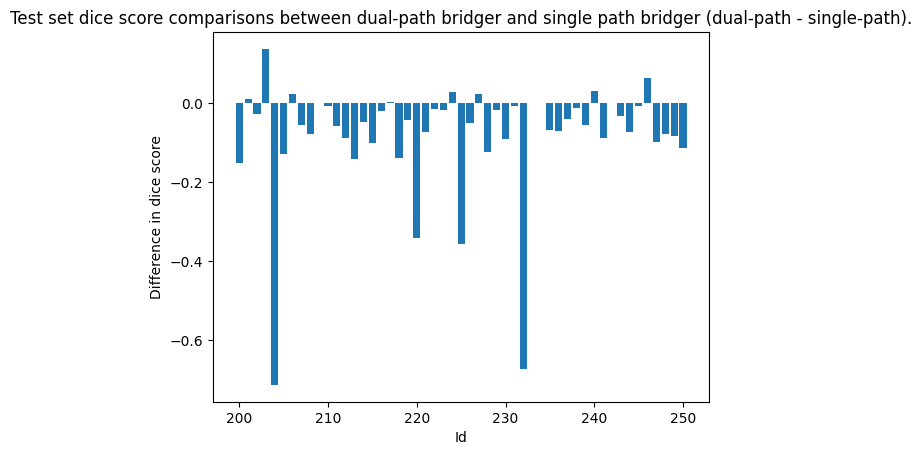

In [20]:
plt.bar(x=df_0_test_m["Id"], height=(df_0_test_m["dice"] - df_1_test_m["dice"]))
plt.xlabel("Id")
plt.ylabel("Difference in dice score")
plt.title("Test set dice score comparisons between dual-path bridger and single path bridger (dual-path - single-path).")
plt.show()

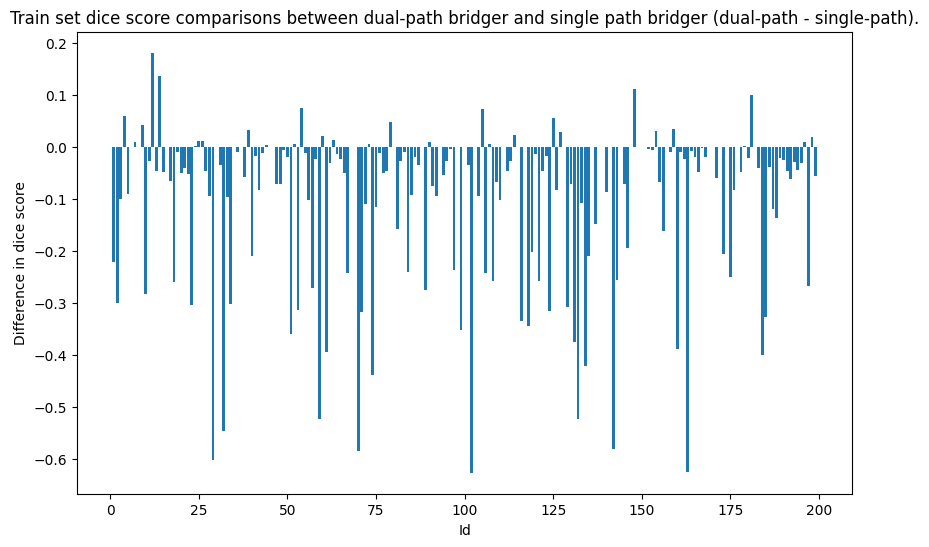

In [21]:
plt.figure(figsize=(10,6))
plt.bar(x=df_0_train_m["Id"], height=(df_0_train_m["dice"] - df_1_train_m["dice"]))
plt.xlabel("Id")
plt.ylabel("Difference in dice score")
plt.title("Train set dice score comparisons between dual-path bridger and single path bridger (dual-path - single-path).")
plt.show()

In [22]:
res_test = wilcoxon(x=df_0_test_m["dice"], y=df_1_test_m["dice"])
print(res_test)

res_train = wilcoxon(x=df_0_train_m["dice"], y=df_1_train_m["dice"])
print(res_train)

WilcoxonResult(statistic=np.float64(132.0), pvalue=np.float64(2.911241451670439e-06))
WilcoxonResult(statistic=np.float64(1471.0), pvalue=np.float64(2.1769171037872767e-18))


In [23]:
res_test = wilcoxon(x=df_0_test_m["F1"], y=df_1_test_m["F1"])
print(res_test)

res_train = wilcoxon(x=df_0_train_m["F1"], y=df_1_train_m["F1"])
print(res_train)

WilcoxonResult(statistic=np.float64(291.0), pvalue=np.float64(0.36138967168222413))
WilcoxonResult(statistic=np.float64(2618.0), pvalue=np.float64(0.016536254756462254))


Fixed Single Path vs Unet

In [76]:
res_test = wilcoxon(x=df_1_test_m["dice"], y=df_21_test_m["dice"])
print(res_test)

res_train = wilcoxon(x=df_1_train_m["dice"], y=df_21_train_m["dice"])
print(res_train)

WilcoxonResult(statistic=np.float64(609.0), pvalue=np.float64(0.7832252432554863))
WilcoxonResult(statistic=np.float64(7878.0), pvalue=np.float64(0.7987554246450655))


In [77]:
res_test = wilcoxon(x=df_1_test_m["F1"], y=df_21_test_m["F1"])
print(res_test)

res_train = wilcoxon(x=df_1_train_m["F1"], y=df_21_train_m["F1"])
print(res_train)

WilcoxonResult(statistic=np.float64(394.0), pvalue=np.float64(0.6362096705104336))
WilcoxonResult(statistic=np.float64(3661.0), pvalue=np.float64(0.0012807396669929332))


Comparing the results of the single path bridger after training pipeline fixes and the UNet shows us that no significant difference exists between the two.

There is a significant difference between the performances in the training set so we analyse the dataset.

In [35]:
# metrics on lesion volume
train_median_vol = have_lesion_train["lesion_vol"].median()
train_mean_vol = have_lesion_train["lesion_vol"].mean()

test_median_vol = have_lesion_test["lesion_vol"].median()
test_mean_vol = have_lesion_test["lesion_vol"].mean()

print(f"Train lesion vol - median:{train_median_vol}, mean:{train_mean_vol}")
print(f"Test lesion vol - median:{test_median_vol}, mean:{test_mean_vol}")

Train lesion vol - median:5.824000276625156, mean:20.669496308678102
Test lesion vol - median:13.944000662304461, mean:35.38547076519415


In [36]:
train_small_lesion_count = have_lesion_train[have_lesion_train["lesion_vol"] < 5].shape[0]
test_small_lesion_count = have_lesion_test[have_lesion_test["lesion_vol"] < 5].shape[0]

print(f"Proportion of small lesions train: {train_small_lesion_count/have_lesion_train.shape[0]}")
print(f"Proportion of small lesions test: {test_small_lesion_count/have_lesion_test.shape[0]}")

Proportion of small lesions train: 0.46938775510204084
Proportion of small lesions test: 0.17647058823529413


### Test of Isles'22 F1 score calculation 

In [16]:
thresholds = [
    ('very small', 0, 5),
    ('medium',     5, 15),
    ('large',      15, 9999)
]

for label, low, high in thresholds:
    for name, df in [('New Single', df_1_test_m),
                     ('UNet',       df_21_test_m),
                     ('Orig Dual',  df_0_test_m),
                     ('Latest Single',  df_8_test_m)]:
        sub = df[(df['lesion_vol'] >= low) & 
                 (df['lesion_vol'] <  high)]
        if len(sub) > 0:
            print(f"{label} ({low}-{high}ml) {name} "
                  f"n={len(sub):2d}  "
                  f"Dice={sub['dice'].mean():.3f}  "
                  f"F1={sub['F1'].mean():.3f}")
    print()

very small (0-5ml) New Single n= 9  Dice=0.328  F1=0.228
very small (0-5ml) UNet n= 9  Dice=0.326  F1=0.142
very small (0-5ml) Orig Dual n= 9  Dice=0.202  F1=0.083
very small (0-5ml) Latest Single n= 9  Dice=0.542  F1=0.613

medium (5-15ml) New Single n=19  Dice=0.563  F1=0.365
medium (5-15ml) UNet n=19  Dice=0.568  F1=0.428
medium (5-15ml) Orig Dual n=19  Dice=0.452  F1=0.416
medium (5-15ml) Latest Single n=19  Dice=0.726  F1=0.582

large (15-9999ml) New Single n=23  Dice=0.719  F1=0.352
large (15-9999ml) UNet n=23  Dice=0.720  F1=0.371
large (15-9999ml) Orig Dual n=23  Dice=0.684  F1=0.373
large (15-9999ml) Latest Single n=23  Dice=0.806  F1=0.596



In [82]:
thresholds = [
    ('very small', 0, 5),
    ('medium',     5, 15),
    ('large',      15, 9999)
]

for label, low, high in thresholds:
    for name, df in [('New Single', df_1_train_m),
                     ('UNet',       df_21_train_m),
                     ('Orig Dual',  df_0_train_m)]:
        sub = df[(df['lesion_vol'] >= low) & 
                 (df['lesion_vol'] <  high)]
        if len(sub) > 0:
            print(f"{label} ({low}-{high}ml) {name} "
                  f"n={len(sub):2d}  "
                  f"Dice={sub['dice'].mean():.3f}  "
                  f"F1={sub['F1'].mean():.3f}")
    print()

very small (0-5ml) New Single n=92  Dice=0.275  F1=0.223
very small (0-5ml) UNet n=92  Dice=0.278  F1=0.248
very small (0-5ml) Orig Dual n=92  Dice=0.169  F1=0.133

medium (5-15ml) New Single n=45  Dice=0.573  F1=0.325
medium (5-15ml) UNet n=45  Dice=0.548  F1=0.374
medium (5-15ml) Orig Dual n=45  Dice=0.440  F1=0.272

large (15-9999ml) New Single n=59  Dice=0.684  F1=0.270
large (15-9999ml) UNet n=59  Dice=0.682  F1=0.340
large (15-9999ml) Orig Dual n=59  Dice=0.630  F1=0.309



In [79]:
mid = df_1_test_m[
    (df_1_test_m['lesion_vol'] >= 5) & 
    (df_1_test_m['lesion_vol'] < 10)]
print(f"5-10ml group (n={len(mid)}):")
print(f"  Dice={mid['dice'].mean():.3f}  "
      f"F1={mid['F1'].mean():.3f}")

5-10ml group (n=10):
  Dice=0.521  F1=0.371


In [44]:
# of the results in the models that are < 10% dice is there a commonality among their lesion volumes?
df_0_test_m_low = df_0_test_m[df_0_test_m["dice"] < 0.1]
df_0_train_m_low = df_0_train_m[df_0_train_m["dice"] < 0.1]

df_25_test_m_low = df_25_test_m[df_25_test_m["dice"] < 0.1]
df_25_train_m_low = df_25_train_m[df_25_train_m["dice"] < 0.1]

df_21_test_m_low = df_21_test_m[df_21_test_m["dice"] < 0.1]
df_21_train_m_low = df_21_train_m[df_21_train_m["dice"] < 0.1]

print(f"In dual {df_0_test_m_low.shape[0]} in test and {df_0_train_m_low.shape[0]} in train.")
print(f"In single {df_25_test_m_low.shape[0]} in test and {df_25_train_m_low.shape[0]} in train.")
print(f"In baseline {df_21_test_m_low.shape[0]} in test and {df_21_train_m_low.shape[0]} in train.")

In dual 10 in test and 75 in train.
In single 12 in test and 88 in train.
In baseline 3 in test and 38 in train.


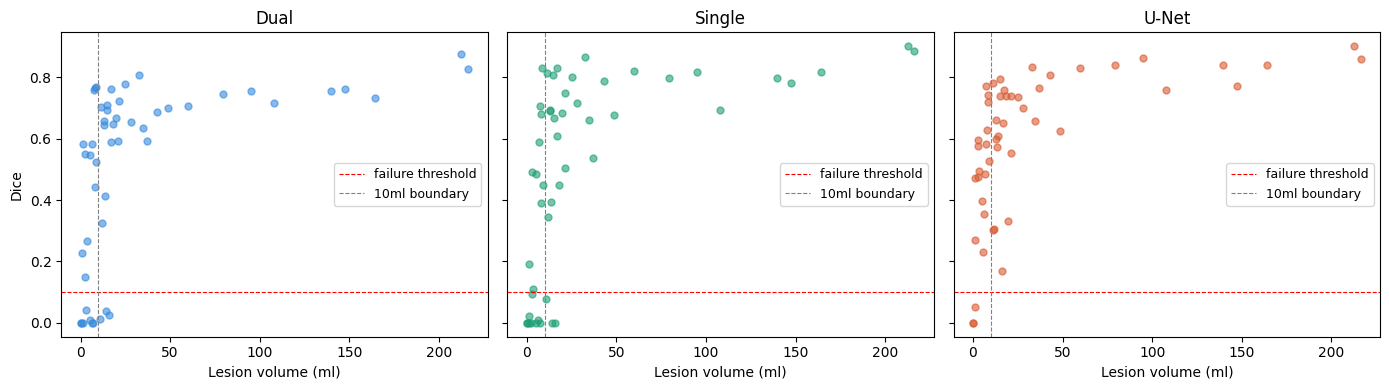

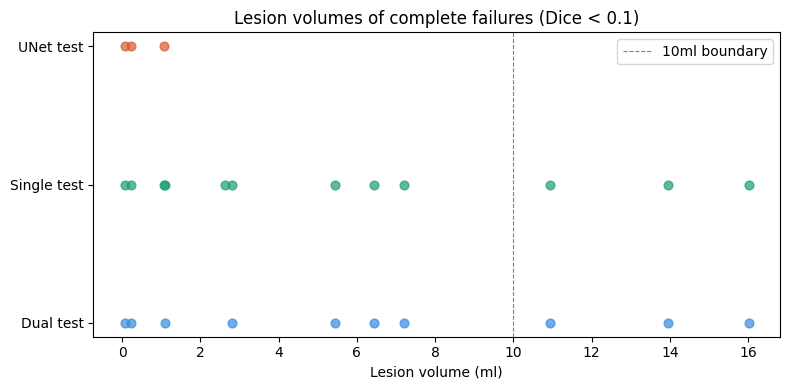

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
models = [
    ('Dual',   df_0_test_m,  '#378ADD'),
    ('Single', df_25_test_m, '#1D9E75'),
    ('U-Net',  df_21_test_m, '#D85A30'),
]

for ax, (name, df, color) in zip(axes, models):
    ax.scatter(df.lesion_vol, df.dice, 
               alpha=0.6, color=color, s=25)
    ax.axhline(0.1, color='red', linewidth=0.8, 
               linestyle='--', label='failure threshold')
    ax.axvline(10, color='gray', linewidth=0.8,
               linestyle='--', label='10ml boundary')
    ax.set_xlabel('Lesion volume (ml)')
    ax.set_ylabel('Dice') if name == 'Dual' else None
    ax.set_title(name)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('dice_vs_vol_failures.png', dpi=150)
plt.show()

# Step 4 — volume distribution of failures across all models
fig, ax = plt.subplots(figsize=(8, 4))
fail_dfs = [
    (df_0_test_m_low,  'Dual test',   '#378ADD'),
    (df_25_test_m_low, 'Single test', '#1D9E75'),
    (df_21_test_m_low, 'UNet test',   '#D85A30'),
]
for df, label, color in fail_dfs:
    if len(df) > 0:
        ax.scatter(df.lesion_vol, 
                   [label] * len(df),
                   alpha=0.7, color=color, s=40)
ax.axvline(10, color='gray', linewidth=0.8, 
           linestyle='--', label='10ml boundary')
ax.set_xlabel('Lesion volume (ml)')
ax.set_title('Lesion volumes of complete failures (Dice < 0.1)')
ax.legend()
plt.tight_layout()
plt.savefig('failure_volumes.png', dpi=150)
plt.show()






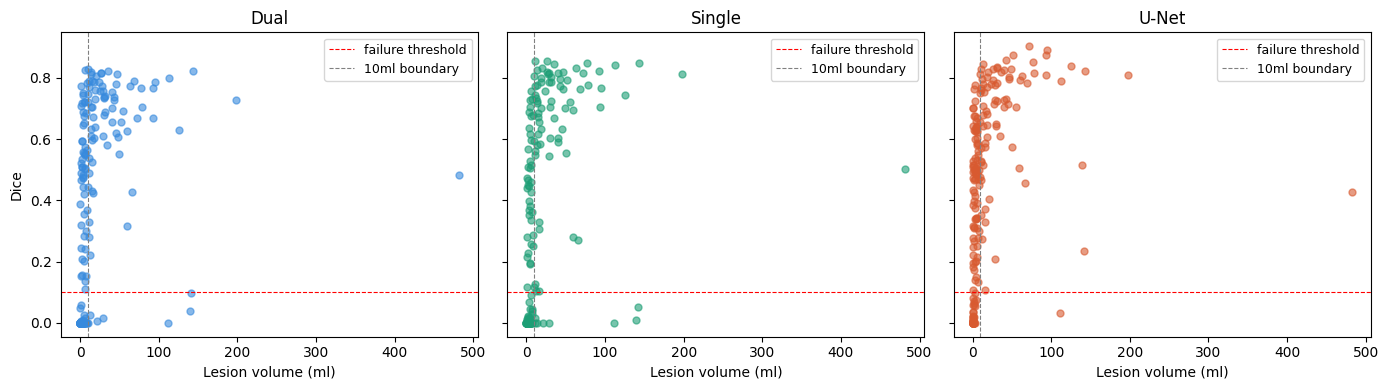

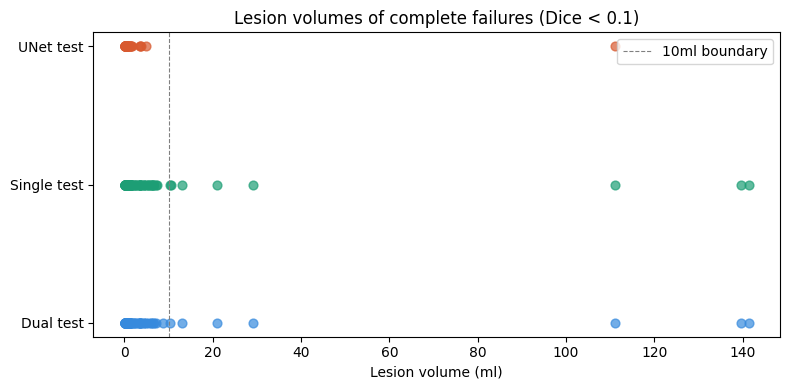

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
models = [
    ('Dual',   df_0_train_m,  '#378ADD'),
    ('Single', df_25_train_m, '#1D9E75'),
    ('U-Net',  df_21_train_m, '#D85A30'),
]

for ax, (name, df, color) in zip(axes, models):
    ax.scatter(df.lesion_vol, df.dice, 
               alpha=0.6, color=color, s=25)
    ax.axhline(0.1, color='red', linewidth=0.8, 
               linestyle='--', label='failure threshold')
    ax.axvline(10, color='gray', linewidth=0.8,
               linestyle='--', label='10ml boundary')
    ax.set_xlabel('Lesion volume (ml)')
    ax.set_ylabel('Dice') if name == 'Dual' else None
    ax.set_title(name)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('dice_vs_vol_failures.png', dpi=150)
plt.show()

# Step 4 — volume distribution of failures across all models
fig, ax = plt.subplots(figsize=(8, 4))
fail_dfs = [
    (df_0_train_m_low,  'Dual test',   '#378ADD'),
    (df_25_train_m_low, 'Single test', '#1D9E75'),
    (df_21_train_m_low, 'UNet test',   '#D85A30'),
]
for df, label, color in fail_dfs:
    if len(df) > 0:
        ax.scatter(df.lesion_vol, 
                   [label] * len(df),
                   alpha=0.7, color=color, s=40)
ax.axvline(10, color='gray', linewidth=0.8, 
           linestyle='--', label='10ml boundary')
ax.set_xlabel('Lesion volume (ml)')
ax.set_title('Lesion volumes of complete failures (Dice < 0.1)')
ax.legend()
plt.tight_layout()
plt.savefig('failure_volumes.png', dpi=150)
plt.show()


### Distribution analysis

In [5]:
raw_data_path = "/home/dayan/Documents/PhD/Objective_1/data/isles_2022_train/"

dirs = os.listdir(raw_data_path)
dirs = sorted(dirs)
dirs = dirs[5:]

img = []
gt = []

voxel_sizes = []
id = 1
for folder in dirs:
    path = f"{raw_data_path}/{folder}/dwi.nii.gz"
    gt_path  = f"{raw_data_path}/{folder}/label.nii.gz"
    dwi_image = nib.load(path).get_fdata()
    gt_image = nib.load(gt_path).get_fdata()
    img.append(dwi_image)
    gt.append(gt_image)


gt = np.array(gt)
lesion_prob = np.mean(gt, axis=0)

plt.imshow(lesion_prob[lesion_prob.shape[0]//2], cmap='hot')
plt.title("Lesion Occurrence Probability")


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (194,) + inhomogeneous part.